# Loan Approval Analysis: Exploratory Data Analysis

**Business question:** Which applicant characteristics drive loan approval, where is the lender
leaving money on the table, and what can the business do to approve more good loans and
protect itself from risky ones?

**Datasets**
- `train.csv`: 614 past loan applications **with** the decision (`Loan_Status`: Y = approved, N = rejected)
- `test.csv`: 367 applications **without** a decision

Because only the training file has the outcome, all approval-rate analysis uses `train.csv`.


In [33]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display and plotting settings
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)
APPROVED_COLOR, REJECTED_COLOR, NEUTRAL = "#55A868", "#C44E52", "#4C72B0"
import warnings
warnings.filterwarnings("ignore")

## Load the data

In [34]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print(f"train: {train.shape[0]} rows x {train.shape[1]} columns")
print(f"test:  {test.shape[0]} rows x {test.shape[1]} columns")
train.head()


train: 614 rows x 13 columns
test:  367 rows x 12 columns


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


## Initial overview

In [35]:
# Missing values as a count per column, train vs test side by side
missing = pd.DataFrame({"train_missing": train.isnull().sum(),"test_missing": test.isnull().sum()})
missing[(missing.train_missing > 0) | (missing.test_missing > 0)]


,train_missing,test_missing
Credit_History,50,29.0
Dependents,15,10.0
Gender,13,11.0
LoanAmount,22,5.0
Loan_Amount_Term,14,6.0
Married,3,0.0
Self_Employed,32,23.0


In [36]:
# Confirm no application appears in both files and no ID is duplicated
print("Duplicate Loan_IDs in train:", train["Loan_ID"].duplicated().sum())
print("Loan_IDs shared between train and test:", len(set(train["Loan_ID"]) & set(test["Loan_ID"])))


Duplicate Loan_IDs in train: 0
Loan_IDs shared between train and test: 0


## Cleaning and preprocessing

We combine train and test so both are cleaned with the **same rules**, then split them apart again.
Decisions made:

In [37]:
# Tag each row with its source, then combine for consistent cleaning
combined = pd.concat([train.assign(source="train"), test.assign(source="test")], ignore_index=True)

In [38]:
# Label small gaps in categorical columns as "Unknown"
for col in ["Gender", "Married", "Dependents", "Self_Employed"]: combined[col] = combined[col].fillna("Unknown")

In [39]:
# Numeric gaps: median for loan amount, mode for term
combined["LoanAmount"] = combined["LoanAmount"].fillna(combined["LoanAmount"].median())
combined["Loan_Amount_Term"] = combined["Loan_Amount_Term"].fillna(combined["Loan_Amount_Term"].mode()[0])

In [40]:
# Credit history: 1 = meets guidelines, 0 = does not, blanks stay "Missing"
combined["Credit_History_Label"] = (combined["Credit_History"].map({1.0: "Meets guidelines", 0.0: "Does not meet"}).fillna("Missing"))

### Feature engineering

Three new columns that translate raw numbers into things a credit officer would actually look at. Note that the repayment figure below is a **simple estimate** (loan amount divided by the number of months, with no interest). It is *not* a true EMI (Equated Monthly Instalment), which would include interest.

In [41]:
# Household income: applicant plus co-applicant
combined["TotalIncome"] = combined["ApplicantIncome"] + combined["CoapplicantIncome"]

In [42]:
# Estimated monthly repayment = loan amount / term in months (LoanAmount is in thousands).
# Simplified: no interest is included, so this is not a true EMI.
combined["Est_Monthly_Repayment"] = combined["LoanAmount"] * 1000 / combined["Loan_Amount_Term"]

In [43]:
# Repayment burden: share of household income that goes to the estimated monthly repayment
combined["Repayment_Burden"] = combined["Est_Monthly_Repayment"] / combined["TotalIncome"]

In [44]:
# Numeric target (1 = approved) for averaging into approval rates
combined["Approved"] = combined["Loan_Status"].map({"Y": 1, "N": 0})

In [45]:
# Back to the labelled training data for analysis
df = combined[combined["source"] == "train"].copy()
print(f"Analysis dataset: {len(df)} applications")

Analysis dataset: 614 applications


In [46]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,source,Credit_History_Label,TotalIncome,Est_Monthly_Repayment,Repayment_Burden,Approved
0,LP001002,Male,No,0,Graduate,No,5849,0.0,126.0,360.0,1.0,Urban,Y,train,Meets guidelines,5849.0,350.000000,0.059839,1.0
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,train,Meets guidelines,6091.0,355.555556,0.058374,0.0
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,train,Meets guidelines,3000.0,183.333333,0.061111,1.0
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,train,Meets guidelines,4941.0,333.333333,0.067463,1.0
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,train,Meets guidelines,6000.0,391.666667,0.065278,1.0


In [47]:
df[["TotalIncome", "Est_Monthly_Repayment", "Repayment_Burden"]].describe().round(3)

,TotalIncome,Est_Monthly_Repayment,Repayment_Burden
count,614.000,614.000,614.000
mean,7024.705,473.465,0.077
std,6458.664,511.157,0.079
min,1442.000,25.000,0.007
25%,4166.000,288.889,0.055
50%,5416.500,361.111,0.069
75%,7521.750,505.556,0.082
max,81000.000,9250.000,1.237


## Overall approval rate

Overall approval rate: 68.7%  (422.0 approved of 614)


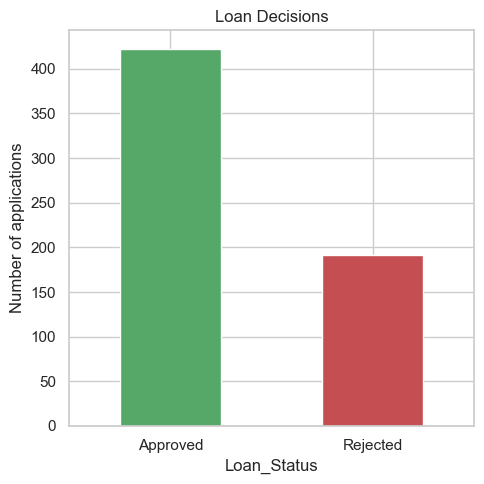

In [48]:
overall_rate = df["Approved"].mean()
print(f"Overall approval rate: {overall_rate:.1%}  ({df['Approved'].sum()} approved of {len(df)})")

plt.figure(figsize=(5, 5))
df["Loan_Status"].map({"Y": "Approved", "N": "Rejected"}).value_counts().plot(
    kind="bar", color=[APPROVED_COLOR, REJECTED_COLOR])
plt.title("Loan Decisions")
plt.ylabel("Number of applications")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Business implication:** About 69% of applications are approved, so roughly 3 in 10 applicants are
turned away.

## What drives approval?

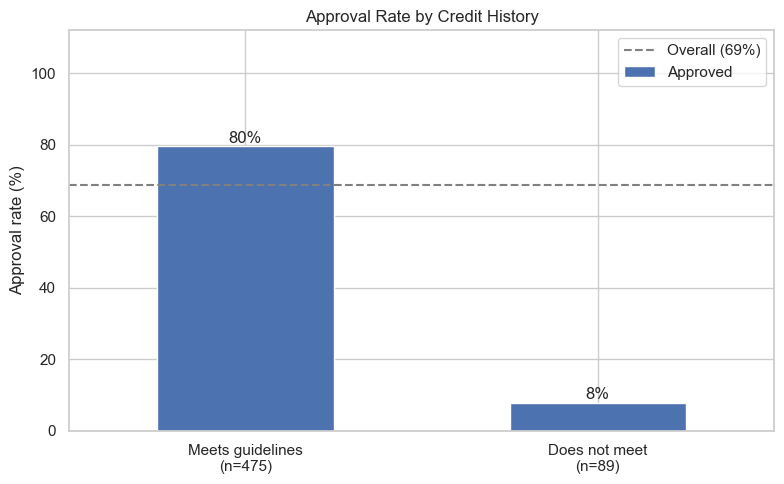

Credit_History_Label
Meets guidelines    79.6
Does not meet        7.9
Name: Approved, dtype: float64

In [49]:
def plot_approval_rate(data, col, title, order=None, color=NEUTRAL):
    """Bar chart of approval rate (%) by a categorical column, with the overall rate as a reference line."""
    data = data[data[col] != "Unknown"]   # exclude "Unknown" so the chart only shows known categories
    rates = data.groupby(col)["Approved"].mean().mul(100)
    counts = data.groupby(col)["Approved"].size()
    if order:
        rates = rates.reindex(order)
        counts = counts.reindex(order)
    ax = rates.plot(kind="bar", color=color, figsize=(8, 5))
    ax.set_xticklabels([f"{lvl}\n(n={counts[lvl]})" for lvl in rates.index])
    ax.axhline(overall_rate * 100, color="grey", linestyle="--", label=f"Overall ({overall_rate:.0%})")
    for i, v in enumerate(rates):
        ax.text(i, v + 1, f"{v:.0f}%", ha="center")
    ax.set_title(title)
    ax.set_ylabel("Approval rate (%)")
    ax.set_xlabel("")
    ax.set_ylim(0, 112)
    ax.legend()
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return rates.round(1)

plot_approval_rate(df, "Credit_History_Label", "Approval Rate by Credit History",
                   order=["Meets guidelines", "Does not meet"], color=NEUTRAL)


**Business implication:** Credit history is by far the strongest driver. Applicants whose credit history
**meets guidelines** are approved about **80%** of the time, while those who **do not meet** guidelines are
approved only **8%** of the time. Credit history is effectively the gatekeeper of the whole approval process.
Note also that applicants with a **missing** credit history are approved 74% of the time, almost as often
as those who meet guidelines, even though we do not know whether they would have met them. That is a policy
worth reviewing.

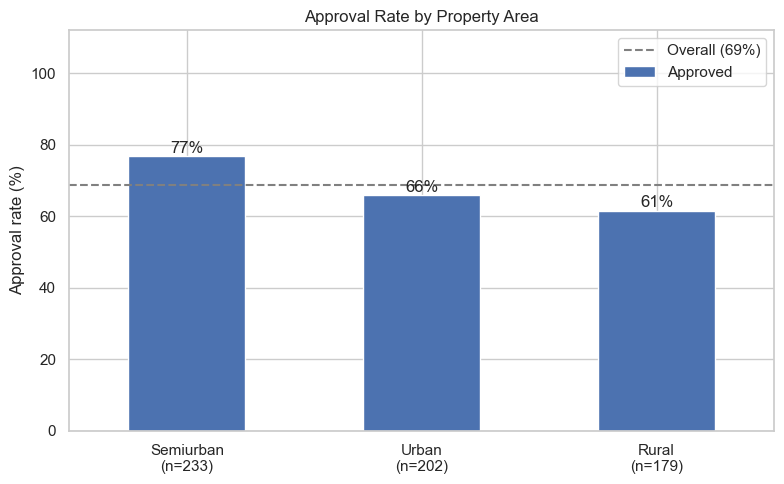

Property_Area
Semiurban    76.8
Urban        65.8
Rural        61.5
Name: Approved, dtype: float64

In [50]:
plot_approval_rate(df, "Property_Area", "Approval Rate by Property Area", order=["Semiurban", "Urban", "Rural"], color=NEUTRAL)


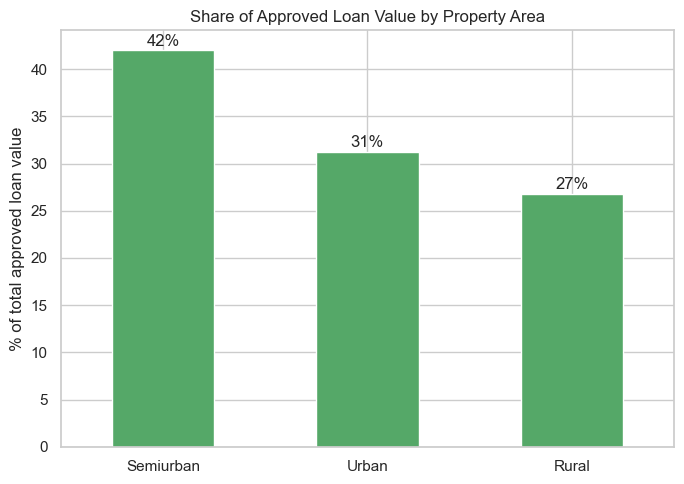

In [51]:
# How much loan value (in thousands) is actually approved in each area?
approved_value = df[df["Approved"] == 1].groupby("Property_Area")["LoanAmount"].sum()
share = (approved_value / approved_value.sum() * 100).sort_values(ascending=False)

ax = share.plot(kind="bar", color=APPROVED_COLOR, figsize=(7, 5))
for i, v in enumerate(share):
    ax.text(i, v + 0.5, f"{v:.0f}%", ha="center")
ax.set_title("Share of Approved Loan Value by Property Area")
ax.set_ylabel("% of total approved loan value")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Business implication:** Semiurban is the lender's sweet spot: the highest approval rate (77%) and about
**42%** of all approved loan value. Rural applicants are approved least often (61%) and account for only
about 27% of approved value, so rural is the area with the most room to grow if risk can be managed.

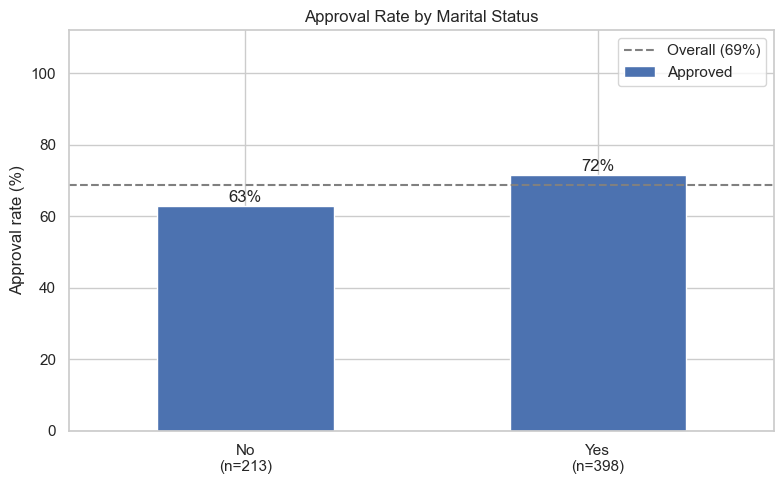

Married
No     62.9
Yes    71.6
Name: Approved, dtype: float64

In [52]:
plot_approval_rate(df, "Married", "Approval Rate by Marital Status", color=NEUTRAL)


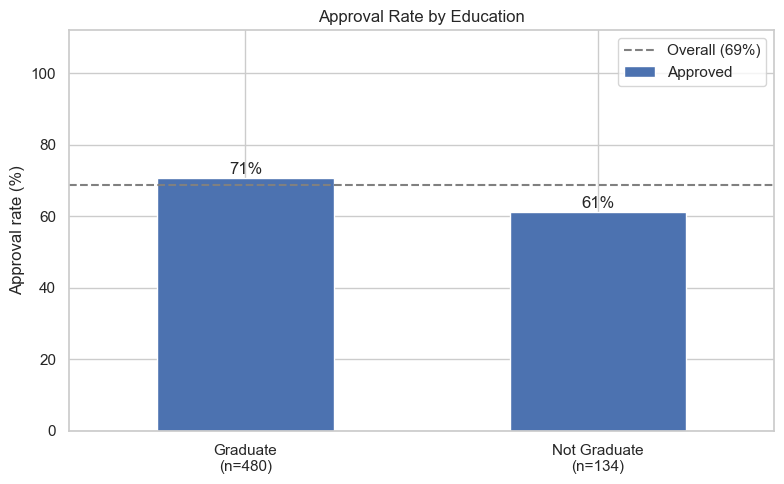

Education
Graduate        70.8
Not Graduate    61.2
Name: Approved, dtype: float64

In [53]:
plot_approval_rate(df, "Education", "Approval Rate by Education", color=NEUTRAL)


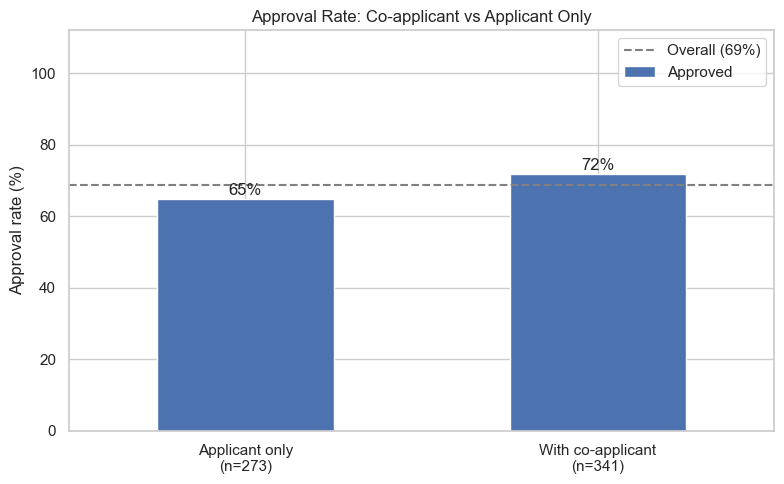

Has_Coapplicant
Applicant only       64.8
With co-applicant    71.8
Name: Approved, dtype: float64

In [54]:
# Does having a co-applicant (someone with extra income) help?
df["Has_Coapplicant"] = np.where(df["CoapplicantIncome"] > 0, "With co-applicant", "Applicant only")
plot_approval_rate(df, "Has_Coapplicant", "Approval Rate: Co-applicant vs Applicant Only",color=NEUTRAL)


**Business implication:** Married applicants (72% vs 63%), graduates (71% vs 61%) and applications with a
co-applicant (72% vs 65%) are approved more often. These groups look like lower-risk, more stable
households to the lender. Encouraging joint applications is a practical way to help borderline
applicants qualify.

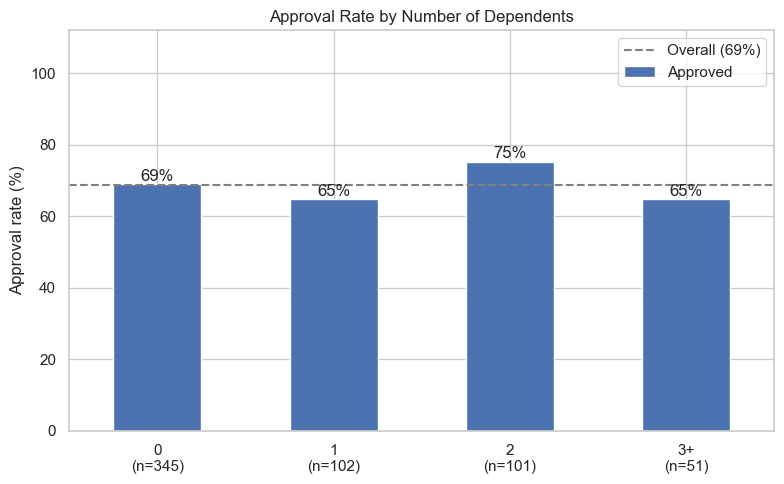

Dependents
0     69.0
1     64.7
2     75.2
3+    64.7
Name: Approved, dtype: float64

In [55]:
plot_approval_rate(df, "Dependents", "Approval Rate by Number of Dependents",order=["0", "1", "2", "3+"], color=NEUTRAL)


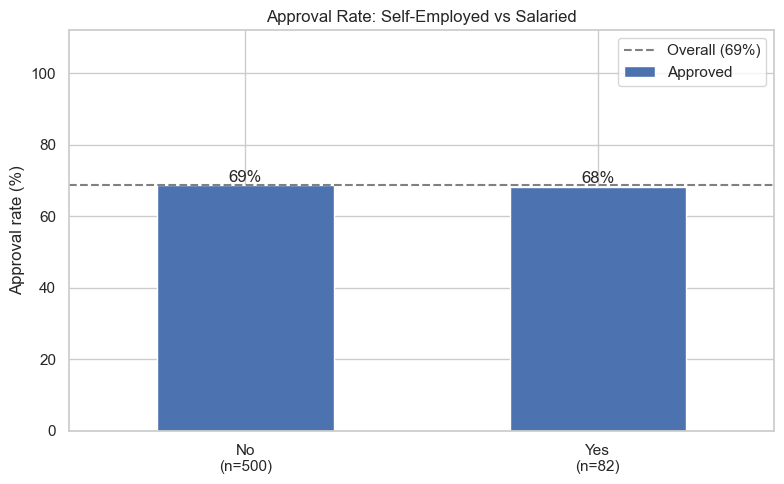

Self_Employed
No     68.6
Yes    68.3
Name: Approved, dtype: float64

In [56]:
plot_approval_rate(df, "Self_Employed", "Approval Rate: Self-Employed vs Salaried",color=NEUTRAL)


**Business implication:** Self-employment makes almost no difference (about 68% either way), so self-employed
applicants are not being unfairly penalised. Dependents show no clear pattern, so household size alone is
not driving decisions.

## Does income or loan size matter?

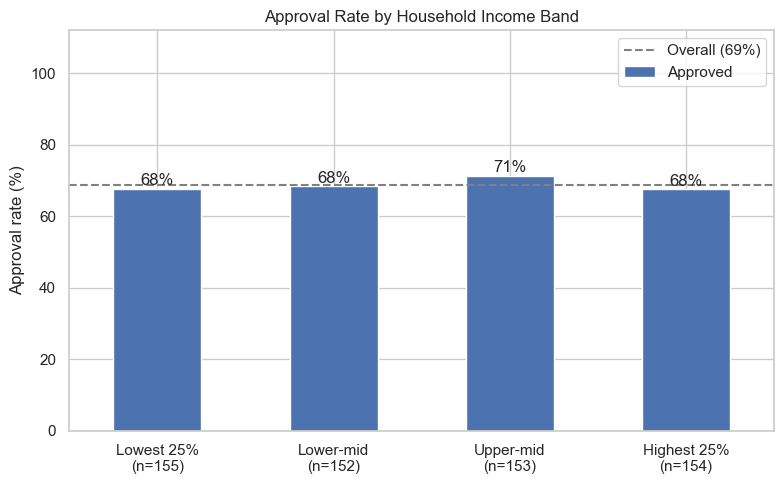

Income_Band
Lowest 25%     67.7
Lower-mid      68.4
Upper-mid      71.2
Highest 25%    67.5
Name: Approved, dtype: float64

In [57]:
# Income is heavily skewed, so group applicants into four equal-sized income bands
df["Income_Band"] = pd.qcut(df["TotalIncome"], 4, labels=["Lowest 25%", "Lower-mid", "Upper-mid", "Highest 25%"])
plot_approval_rate(df, "Income_Band", "Approval Rate by Household Income Band",color=NEUTRAL)


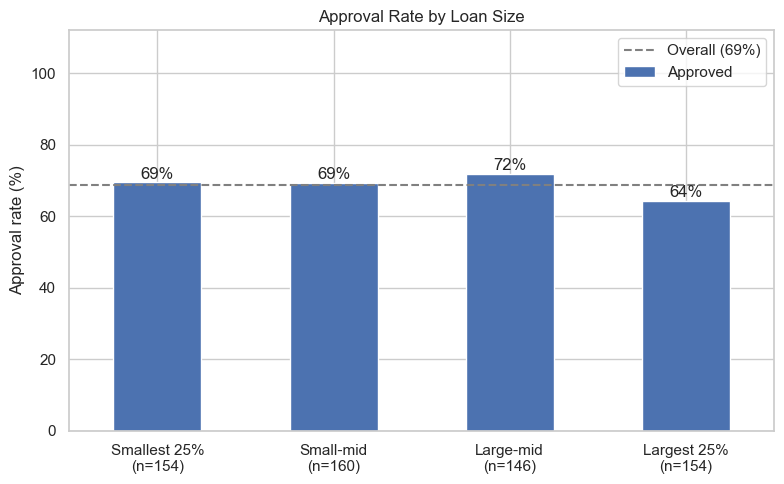

Loan_Size_Band
Smallest 25%    69.5
Small-mid       69.4
Large-mid       71.9
Largest 25%     64.3
Name: Approved, dtype: float64

In [58]:
df["Loan_Size_Band"] = pd.qcut(df["LoanAmount"], 4, labels=["Smallest 25%", "Small-mid", "Large-mid", "Largest 25%"])
plot_approval_rate(df, "Loan_Size_Band", "Approval Rate by Loan Size",color=NEUTRAL)


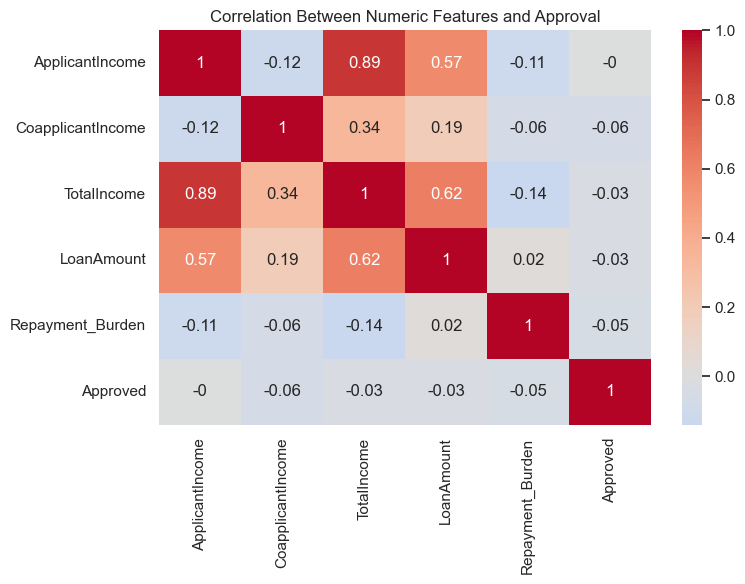

In [59]:
# Correlation of numeric features with the approval outcome
num_cols = ["ApplicantIncome", "CoapplicantIncome", "TotalIncome", "LoanAmount", "Repayment_Burden", "Approved"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr().round(2), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features and Approval")
plt.tight_layout()
plt.show()


**Business implication:** Income, loan size and repayment burden have almost **no correlation** with approval
(all close to zero).

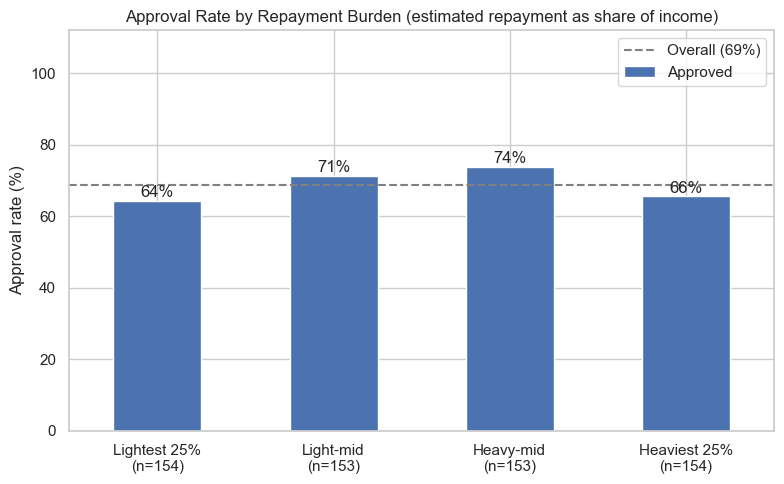

Burden_Band
Lightest 25%    64.3
Light-mid       71.2
Heavy-mid       73.9
Heaviest 25%    65.6
Name: Approved, dtype: float64

In [60]:
# Repayment burden: how stretched is the borrower? Compare approval across burden bands
df["Burden_Band"] = pd.qcut(df["Repayment_Burden"], 4, labels=["Lightest 25%", "Light-mid", "Heavy-mid", "Heaviest 25%"])
plot_approval_rate(df, "Burden_Band", "Approval Rate by Repayment Burden (estimated repayment as share of income)",color=NEUTRAL)


**Business implication:** Even the applicants with the heaviest repayment burden are still approved about 66% of
the time, close to the overall rate. Affordability is not acting as a strong filter. Adding an
explicit affordability check would help protect the lender from stretched borrowers.

## Where is the lender losing good business?

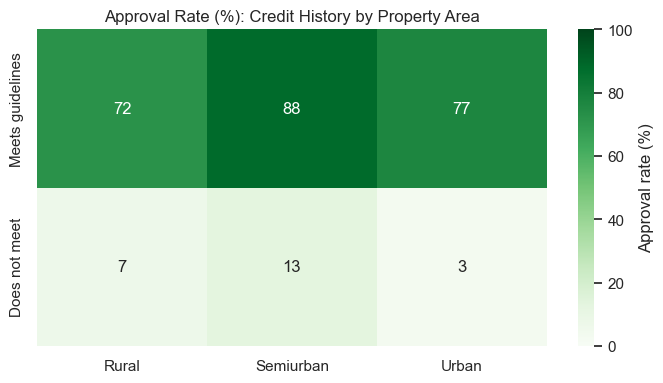

In [61]:
# Combine the two strongest factors: credit history x property area
pivot = df.pivot_table(index="Credit_History_Label", columns="Property_Area", values="Approved", aggfunc="mean").mul(100).round(0)
pivot = pivot.reindex(["Meets guidelines", "Does not meet"])

plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="Greens", vmin=0, vmax=100,cbar_kws={"label": "Approval rate (%)"})
plt.title("Approval Rate (%): Credit History by Property Area")
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()
plt.show()


In [62]:
# Applicants whose credit history MEETS guidelines who were still rejected: a potential missed-revenue pool
missed = df[(df["Credit_History_Label"] == "Meets guidelines") & (df["Approved"] == 0)]
print(f"Applicants meeting credit guidelines but rejected: {len(missed)}")
print(f"Total loan value requested by them: {missed['LoanAmount'].sum():,.0f} (thousands)")
print(f"Average requested loan: {missed['LoanAmount'].mean():,.0f} (thousands)")
print()
print("Share of those rejections by area:")
print(missed["Property_Area"].value_counts(normalize=True).mul(100).round(0))


Applicants meeting credit guidelines but rejected: 97
Total loan value requested by them: 14,916 (thousands)
Average requested loan: 154 (thousands)

Share of those rejections by area:
Property_Area
Rural        40.0
Urban        36.0
Semiurban    24.0
Name: proportion, dtype: float64


In [63]:
# Among applicants who meet credit guidelines: who is still being rejected most often?
good = df[df["Credit_History_Label"] == "Meets guidelines"]
rows = []
for col in ["Property_Area", "Married", "Education"]:
    for level, rate in good.groupby(col)["Approved"].mean().mul(100).items():
        rows.append({"Segment": f"{col}: {level}", "Approval rate when credit history meets guidelines (%)": round(rate, 1)})
pd.DataFrame(rows).sort_values("Approval rate when credit history meets guidelines (%)")


,Segment,Approval rate when credit history meets guidelines (%)
0,Property_Area: Rural,71.5
3,Married: No,73.1
7,Education: Not Graduate,74.7
2,Property_Area: Urban,76.8
6,Education: Graduate,80.8
5,Married: Yes,83.0
1,Property_Area: Semiurban,87.7
4,Married: Unknown,100.0


**Business implication:** 97 applicants whose credit history meets guidelines were still rejected. They asked
for about **14,900 (thousand)** in loans, roughly 154 each on average. That is genuine lost business. Among
these applicants, rejections are most common for **rural** (72% approved vs 88% semiurban),
**unmarried** (73% vs 83% married) and **non-graduate** (75% vs 81% graduate) applicants, so these are the
groups where a second look is most likely to recover profitable loans.

## Loan term

In [64]:
term_counts = df["Loan_Amount_Term"].value_counts(normalize=True).mul(100).round(1)
print("Share of applications by loan term (months):")
print(term_counts)
print()
print(df.groupby("Loan_Amount_Term")["Approved"].agg(["mean", "count"]).round(2))


Share of applications by loan term (months):
Loan_Amount_Term
360.0    85.7
180.0     7.2
480.0     2.4
300.0     2.1
84.0      0.7
240.0     0.7
120.0     0.5
60.0      0.3
36.0      0.3
12.0      0.2
Name: proportion, dtype: float64

                  mean  count
Loan_Amount_Term             
12.0              1.00      1
36.0              0.00      2
60.0              1.00      2
84.0              0.75      4
120.0             1.00      3
180.0             0.66     44
240.0             0.75      4
300.0             0.62     13
360.0             0.70    526
480.0             0.40     15


**Business implication:** About 86% of applications are for the standard 360-month (30 year) term, so the
product is highly concentrated. Other terms have too few applications (15 or fewer each, except 180 months)
to draw firm conclusions, but the 480-month term shows a notably lower approval rate (about 40%).

## Key Insights

1. **Credit history decides the outcome.** Applicants who meet credit guidelines are approved about 80% of the
   time versus 8% for those who do not. Income and loan size have almost no relationship with approval.
2. **Semiurban is the lender's strongest market**: highest approval rate (77%) and about 42% of approved
   loan value. Rural is the weakest (61% approved, about 27% of approved value) and the biggest growth gap.
3. **Money is being left on the table.** 97 applicants meeting credit guidelines (about 14,900 thousand in requested
   loans) were rejected, disproportionately rural, unmarried or non-graduate applicants.
4. **Stable households are favoured.** Married applicants, graduates and applications with a co-applicant
   are approved more often, even when credit history is the same.
5. **Affordability is not a strong filter.** Applicants with the heaviest repayment burden are still
   approved about 66% of the time, so the lender may be exposed to stretched borrowers.
6. **Applicants with a missing credit history are approved 74% of the time**, almost as often as those who
   meet guidelines, even though their risk is unknown.
7. **The product is concentrated**: about 86% of applications are for the standard 30-year term.

## Recommendations

1. **Fast-track applicants who meet credit guidelines.** Since credit history is the real gatekeeper, build an
   automated quick-approval path for applicants who meet guidelines and have a healthy repayment burden. This speeds up
   approvals, lowers processing cost and wins customers before competitors do.
2. **Add a second-look review for rejected applicants who meet credit guidelines**, especially rural, unmarried and
   non-graduate applicants. Recovering even a share of the 97 rejected loans is direct revenue gain.
3. **Grow in semiurban areas and build a rural strategy.** Put marketing weight behind semiurban, where
   conversion and loan value are highest, and design rural products (for example, community guarantors or
   seasonal income terms) to lift the 61% rural approval rate safely.
4. **Encourage joint applications.** Offer co-applicant options to borderline applicants, since applications
   with a co-applicant are approved more often and carry extra repayment capacity.
5. **Add an affordability test next to the credit check.** Cap the repayment burden (estimated monthly repayment as a share of
   income) so stretched borrowers are screened out and defaults are reduced.
6. **Set a clear policy for applicants with a missing credit history.** Approving them at nearly the same rate
   as applicants who meet guidelines carries hidden risk. Use smaller starter loans or extra documentation, and
   treat them as a customer-acquisition opportunity.
7. **Test alternative loan terms.** With 86% of demand on one term, pilot shorter or more flexible terms
   to reach applicants who are not served by the standard product.

## Conclusion

This analysis shows that loan approval in this portfolio is driven overwhelmingly by credit history, with
household stability (marriage, education, co-applicant) and location (semiurban strongest) playing a
supporting role, while income and loan size matter very little. The business opportunity is twofold:
**recover profitable loans** that are currently rejected despite meeting credit guidelines, and **tighten risk control**
where approvals ignore affordability or lack credit data. Acting on these recommendations would grow the
loan book in its strongest segments, open up the under-served rural market, and reduce exposure to
risky borrowers. The next step is to build a predictive model on this data to automate and test these
decision rules.